# Журнал состояний, версия 2: результаты — вся история (без окна)

Чем отличается от версии 1 (`petri_states_results_all.ipynb`, папка `out_states\`; её результаты не менялись):

| | Версия 1 | Версия 2 |
|---|---|---|
| Флаги | `SHORT` = 15, `LONG` = 365 | `SHORT` = 15, `LONG` = **180** (подобраны в `petri_states_flags.ipynb`) |
| Переход в `end` | только из `free`, `jail`, `prison`; иначе перед `end` ставится возврат в заключение | из `free`, из **любого состояния с заключением** (`charge+prison` и т. п.), из ареста/обвинения — **если оно в день конца наблюдения или накануне** (тогда `free` не ставится) |
| Оценка | все майнеры на всём журнале; лучшие — train/test + alignments | **все майнеры на train/test**, TBR fitness и ETC precision, без alignments |

| Что | Файл |
|---|---|
| Расчёт (журнал, майнеры, метрики) | `run_states_v2.py` |
| Правило `end` (параметр `end_rule="v2"`) | `petri_states.py` → `build_state_log`, `check_state_log` |
| Этот ноутбук (генератор) | `make_notebook_results_v2.py` |
| Результаты | `out_states_v2\all\`: `state_log.csv`, `report.json`, `split_quality.csv`, `discovery_info.csv`, `net_*.png`, `dfg_*.png` |

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

EXP = "all"
V2 = Path("out_states_v2") / EXP
V1 = Path("out_states") / EXP
BEST = ["flower", "DFG_p0.05", "HM_dep0.95", "SplitMiner", "IM_noise0.2"]
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 40)

def state_log(d):
    p = d / "state_log.csv"
    return pd.read_csv(p if p.exists() else d / "state_log.csv.gz", parse_dates=["ts", "ts_raw"])


log2 = state_log(V2)
log1 = state_log(V1)
rep = json.loads((V2 / "report.json").read_text(encoding="utf-8"))
q2 = pd.read_csv(V2 / "split_quality.csv")
print("журнал v2:", f"{len(log2):,} событий, {log2.person_id.nunique():,} трасс")
print("журнал v1:", f"{len(log1):,} событий, {log1.person_id.nunique():,} трасс")

журнал v2: 241,738 событий, 11,473 трасс
журнал v1: 241,319 событий, 11,473 трасс


## 1. Правила, которые изменились

**Правило 5 — `LONG_CUSTODY_DAYS` = 180.** Одно дело в день входа и эпизод заключения от 180 дней —
дело отдельным состоянием перед заключением (`arrest → jail`); короче 180 дней — составное (`arrest+jail`, правило 3).

**Правило 12 — переход в `end`:**
- из `free`;
- из любого состояния, в названии которого есть заключение: `jail`, `prison`, `arrest+jail`, `charge+prison`, …;
- из ареста/обвинения без заключения (`arrest`, `charge`, `arrest+charge`) — только если оно в день
  конца наблюдения или накануне: `free` в D+1 тогда не ставится, следующего дня в данных нет;
- дело внутри срока у того, кто ещё сидит, в последние два дня — тоже сразу в `end`, без возврата в заключение.

Конец наблюдения и «последние два дня»:

In [2]:
obs_end = pd.Timestamp(rep["obs_end"])
print("конец наблюдения:", obs_end, "| дела с", (obs_end.normalize() - pd.Timedelta(days=1)).date(), "идут сразу в end")
print("переходов в end из дела (без free):", rep["end_from_case"])
print("переходов в end из составного состояния:", rep["end_from_composite"])
for line in rep["checks"]:
    print("проверка:", line)

конец наблюдения: 2016-04-19 07:19:36 | дела с 2016-04-18 идут сразу в end
переходов в end из дела (без free): 0
переходов в end из составного состояния: 2
проверка: время внутри каждой трассы строго возрастает
проверка: перед end: {'free': 10786, 'prison': 647, 'jail': 38, 'arrest+jail': 1, 'arrest+charge+jail': 1}
проверка: перед end без заключения и не free: 0, из них не в последние 2 дня: 0
проверка: free → free подряд: 0


### 1.1. Что стоит перед `end`: версия 1 и версия 2

In [3]:
before = pd.concat({"v1": log1.loc[log1.next_activity == "end", "activity"].value_counts(),
                    "v2": log2.loc[log2.next_activity == "end", "activity"].value_counts()}, axis=1).fillna(0).astype(int)
before.sort_values("v2", ascending=False)

,v1,v2
activity,,
free,10786,10786
prison,647,647
jail,40,38
arrest+jail,0,1
arrest+charge+jail,0,1


### 1.2. Примеры трасс: конец трассы в версии 1 и версии 2

Люди, у которых в версии 2 трасса заканчивается не из `free` / `jail` / `prison`. Показаны последние 4 состояния.

In [4]:
cols = ["person_id", "activity", "ts_raw", "kind"]
pre2 = log2[log2.next_activity == "end"]
pick = pd.concat([pre2[pre2.kind == "case"].head(2), pre2[pre2.kind == "inside"].head(1),
                  pre2[pre2.kind == "custody"].loc[lambda x: ~x.activity.isin(["jail", "prison"])].head(2)])
for p in pick.person_id:
    t1 = log1[log1.person_id == p].tail(4)[cols].assign(версия="v1")
    t2 = log2[log2.person_id == p].tail(4)[cols].assign(версия="v2")
    print(f"человек {p}:")
    print("  v1:", " → ".join(f"{a} ({t:%d.%m.%Y})" for a, t in zip(t1.activity, t1.ts_raw)))
    print("  v2:", " → ".join(f"{a} ({t:%d.%m.%Y})" for a, t in zip(t2.activity, t2.ts_raw)))

человек 7278:
  v1: free (17.12.2015) → arrest+jail (06.01.2016) → jail (19.04.2016) → end (19.04.2016)
  v2: arrest+charge+jail (16.12.2015) → free (17.12.2015) → arrest+jail (06.01.2016) → end (19.04.2016)
человек 10045:
  v1: free (31.01.2015) → arrest+charge+jail (22.12.2015) → jail (19.04.2016) → end (19.04.2016)
  v2: charge (30.01.2015) → free (31.01.2015) → arrest+charge+jail (22.12.2015) → end (19.04.2016)


## 2. Журнал: показатели и состояния (версия 1 и версия 2)

- `composite` — составных состояний «дело + заключение» (правило 3);
- `absorbed_units` — дел внутри коротких сроков, склеенных с заключением (правило 6);
- `inside_units` / `returns` — дел внутри срока и возвратов в заключение (правило 7);
- `free_after_case` / `free_after_custody` — выходов в `free` после дела и после заключения;
- `end_from_case` / `end_from_composite` — переходов в `end` из дела и из составного состояния (только v2).

In [5]:
keys = ["composite", "absorbed_units", "inside_units", "returns", "free_after_case", "free_after_custody",
        "no_free_next_day", "started_inside", "end_from_case", "end_from_composite", "events", "people", "activities"]
pd.DataFrame({"v2": [rep.get(k) for k in keys]}, index=keys)

,v2
composite,12806
absorbed_units,181
inside_units,1609
returns,1371
free_after_case,74375
free_after_custody,24305
no_free_next_day,239
started_inside,0
end_from_case,0
end_from_composite,2


In [6]:
acts = pd.concat({"v1": log1.activity.value_counts(), "v2": log2.activity.value_counts()}, axis=1).fillna(0).astype(int)
acts["разница"] = acts.v2 - acts.v1
acts.sort_values("v2", ascending=False)

,v1,v2,разница
activity,,,
free,98680,98680,0
charge,45604,45605,1
arrest,31255,31512,257
arrest+charge,26698,26862,164
end,11473,11473,0
jail,9146,9564,418
arrest+charge+jail,8495,8331,-164
prison,5167,5168,1
arrest+jail,4760,4503,-257


## 3. Все майнеры: train/test 80/20, token replay

- люди делятся 80/20 (seed 42): сеть строится на train, метрики — на train и test;
- `fitness_tbr_train` / `fitness_tbr_test` — fitness token-based replay; `pct_fit_traces_tbr_test` — % трасс test без ошибок;
- `precision_etc_test` — precision ETC на test;
- `precision_norm_test = (P − P_flower) / (1 − P_flower)`: 0 — не лучше цветочной сети, 1 — максимум;
- `f1_tbr = 2·fitness_test·precision / (fitness_test + precision)`.

In [7]:
cols = [k for k in ["model", "places", "transitions", "silent", "fitness_tbr_train", "fitness_tbr_test",
                    "pct_fit_traces_tbr_test", "precision_etc_test", "precision_norm_test", "f1_tbr", "error"]
        if k in q2.columns]
q2[cols].sort_values("f1_tbr", ascending=False).set_index("model")

,places,transitions,silent,fitness_tbr_train,fitness_tbr_test,pct_fit_traces_tbr_test,precision_etc_test,precision_norm_test,f1_tbr
model,,,,,,,,,
SplitMiner,21,35,23,0.761,0.761,7.407,0.811,7.618e-01,0.785
DFG_p0.05,14,34,1,0.958,0.958,50.065,0.620,5.220e-01,0.753
IM_noise0.2,30,41,31,0.984,0.984,33.115,0.453,3.132e-01,0.621
HM_dep0.9,16,43,31,0.984,0.984,0.000,0.358,1.934e-01,0.525
HM_dep0.99,16,43,31,0.984,0.984,0.000,0.358,1.934e-01,0.525
HM_dep0.95,16,43,31,0.984,0.984,0.000,0.358,1.934e-01,0.525
DFG_p0.0,14,83,1,1.000,1.000,100.000,0.262,7.243e-02,0.415
IM_noise0.0,42,52,40,1.000,1.000,99.956,0.213,1.106e-02,0.351
POWL,26,28,16,1.000,1.000,99.956,0.204,1.408e-04,0.339


## 4. Сравнение с версией 1 (лучшие модели, train/test)

Версия 1 — `out_states\<эксперимент>\split_eval.jsonl` (флаги 15 / 365, старое правило `end`).
Разбиение то же (seed 42), но набор людей может немного отличаться: в окне 2013 трассы без событий
в окне отбрасываются, а это зависит от правил журнала.

In [8]:
se = pd.DataFrame([json.loads(l) for l in (V1 / "split_eval.jsonl").read_text(encoding="utf-8").splitlines() if l.strip()])


def prep(q, fa="fitness_tbr_test"):
    pf = float(q.loc[q.model == "flower", "precision_etc_test"].iloc[0])
    q = q.set_index("model").reindex(BEST)
    out = pd.DataFrame({"fitness TBR test": q[fa], "precision test": q["precision_etc_test"]})
    out["precision норм."] = (out["precision test"] - pf) / (1 - pf)
    out["F1 TBR"] = 2 * out["fitness TBR test"] * out["precision test"] / (out["fitness TBR test"] + out["precision test"])
    out.loc["flower", ["precision норм.", "F1 TBR"]] = None
    return out


cmp = pd.concat({"v1": prep(se), "v2": prep(q2)}, axis=1)
for m in ["fitness TBR test", "precision test", "precision норм.", "F1 TBR"]:
    cmp[("v2 − v1", m)] = cmp[("v2", m)] - cmp[("v1", m)]
cmp.round(3)

v1                                                     v2                                                v2 − v1                                      
            fitness TBR test precision test precision норм. F1 TBR fitness TBR test precision test precision норм. F1 TBR fitness TBR test precision test precision норм. F1 TBR
model                                                                                                                                                                           
flower                 1.000          0.189             NaN    NaN            1.000          0.204             NaN    NaN            0.000          0.016             NaN    NaN
DFG_p0.05              0.958          0.620           0.531  0.752            0.958          0.620           0.522  0.753            0.001          0.000          -0.009  0.000
HM_dep0.95             0.984          0.358           0.209  0.525            0.984          0.358           0.193  0.525            0.000         -0.000          -0.016 -0.000
SplitMiner             0.720          0.884           0.857  0.793            0.761          0.811           0.762  0.785            0.041         -0.073          -0.095 -0.009
IM_noise0.2            0.984          0.453           0.326  0.621            0.984          0.453           0.313  0.621            0.000          0.000          -0.013  0.000

## 5. Сети лучших моделей (построены на train) и DFG (весь журнал)

DFG_p0.05


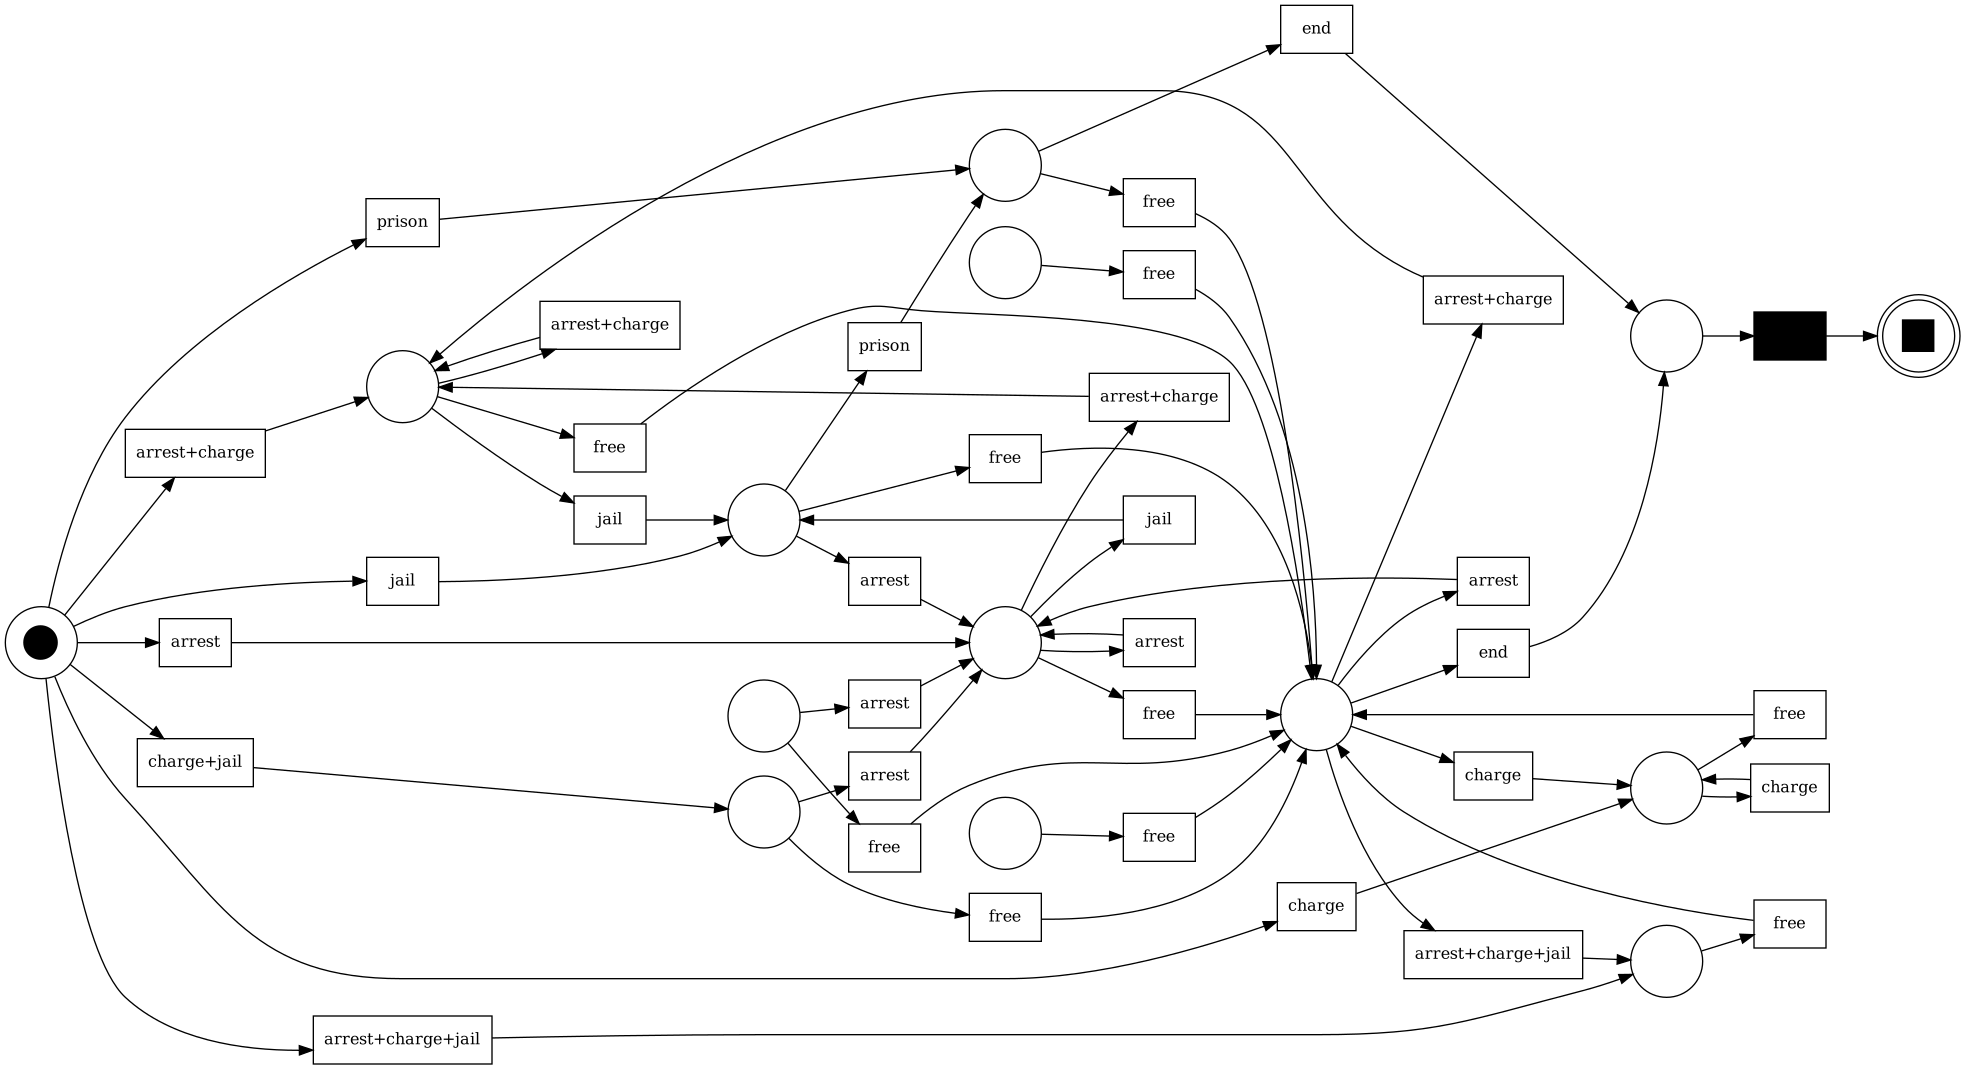

HM_dep0.95


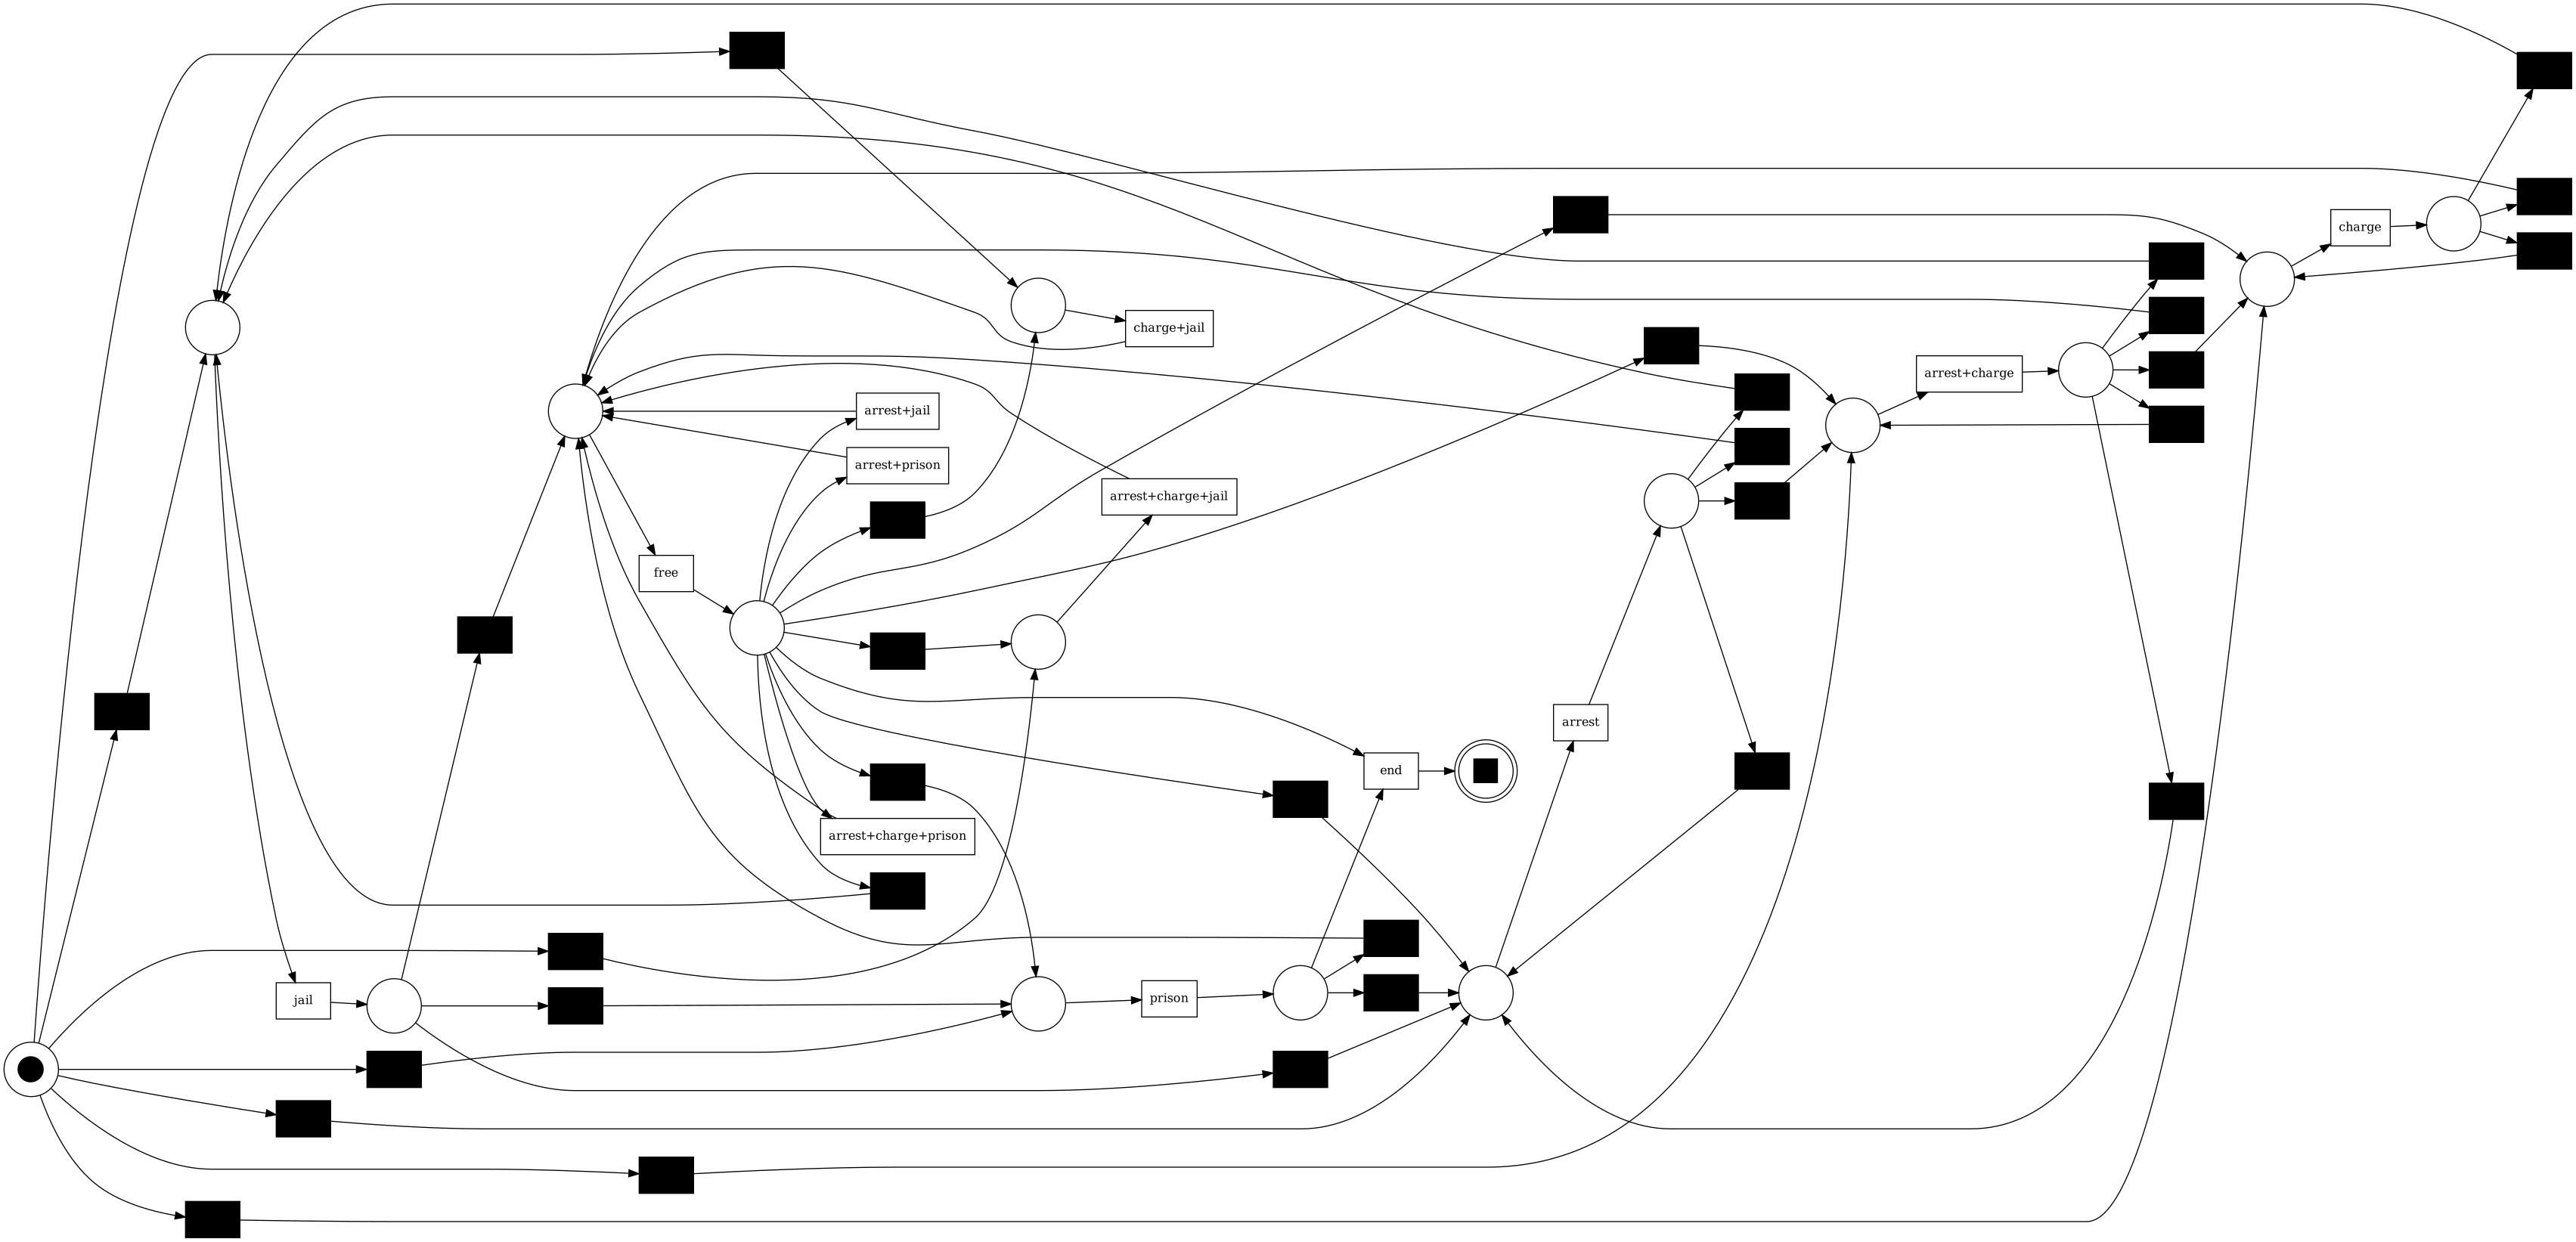

SplitMiner


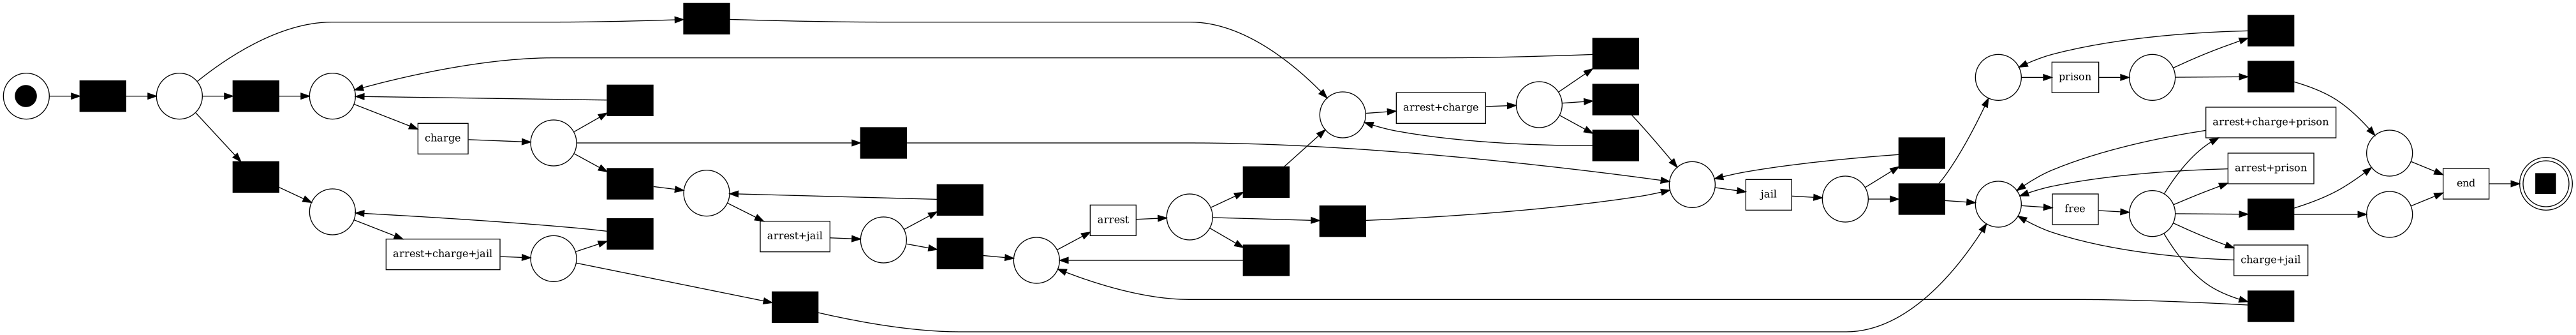

IM_noise0.2


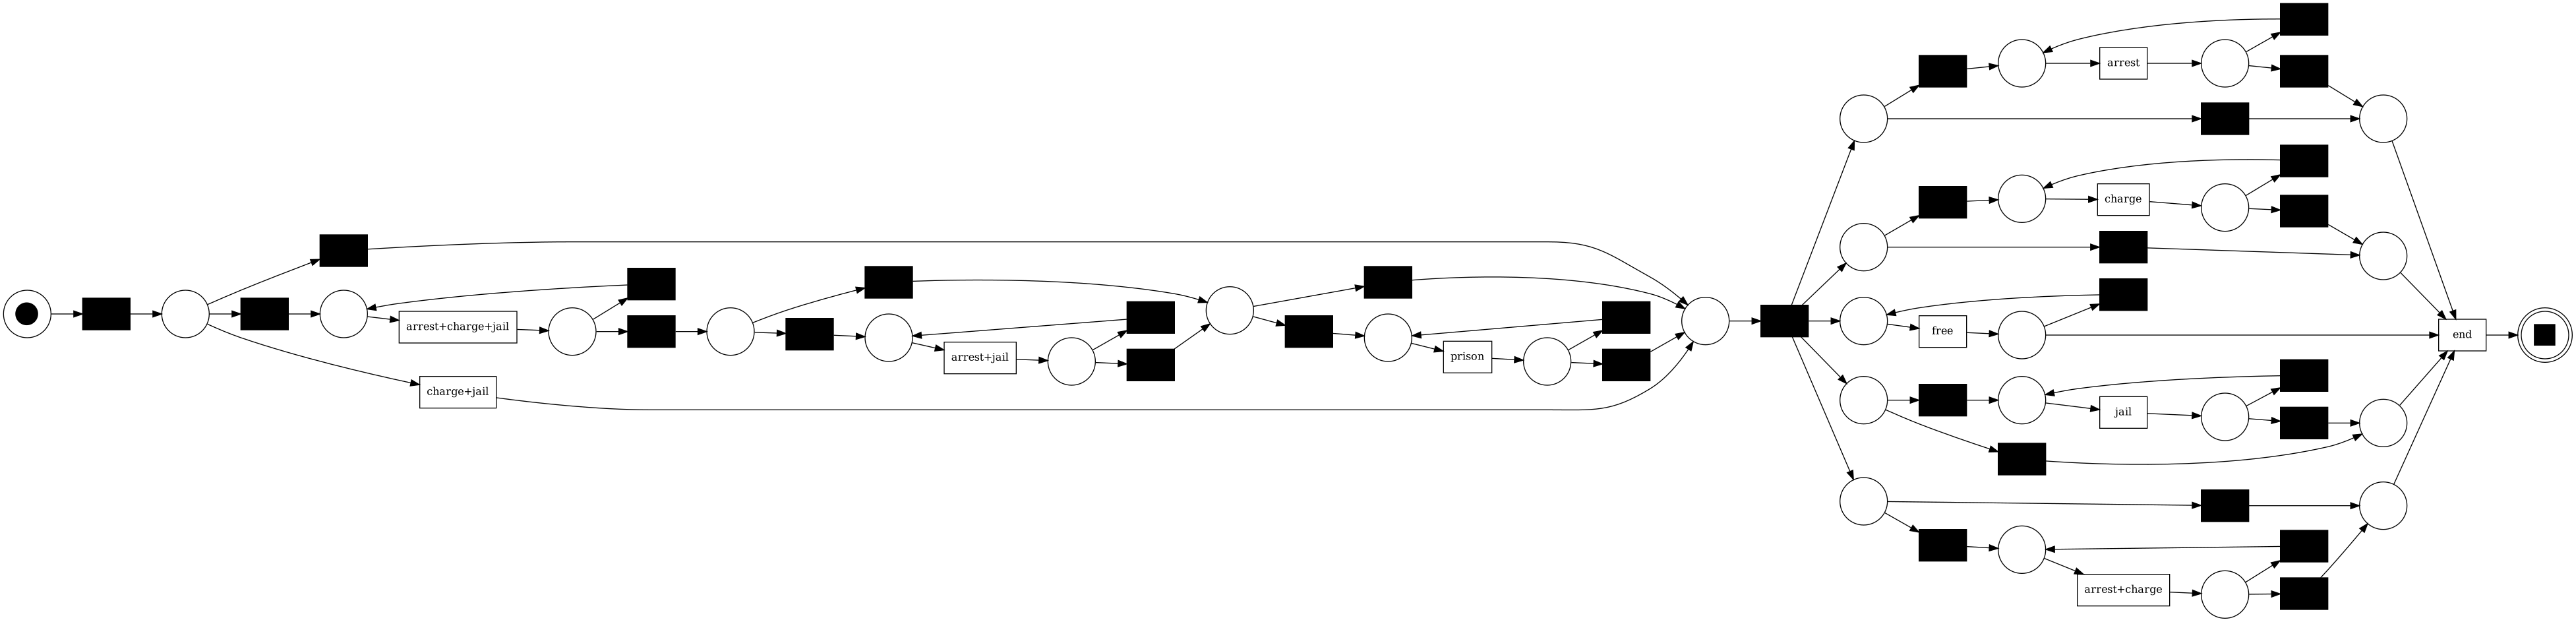

DFG, частоты (весь журнал v2)


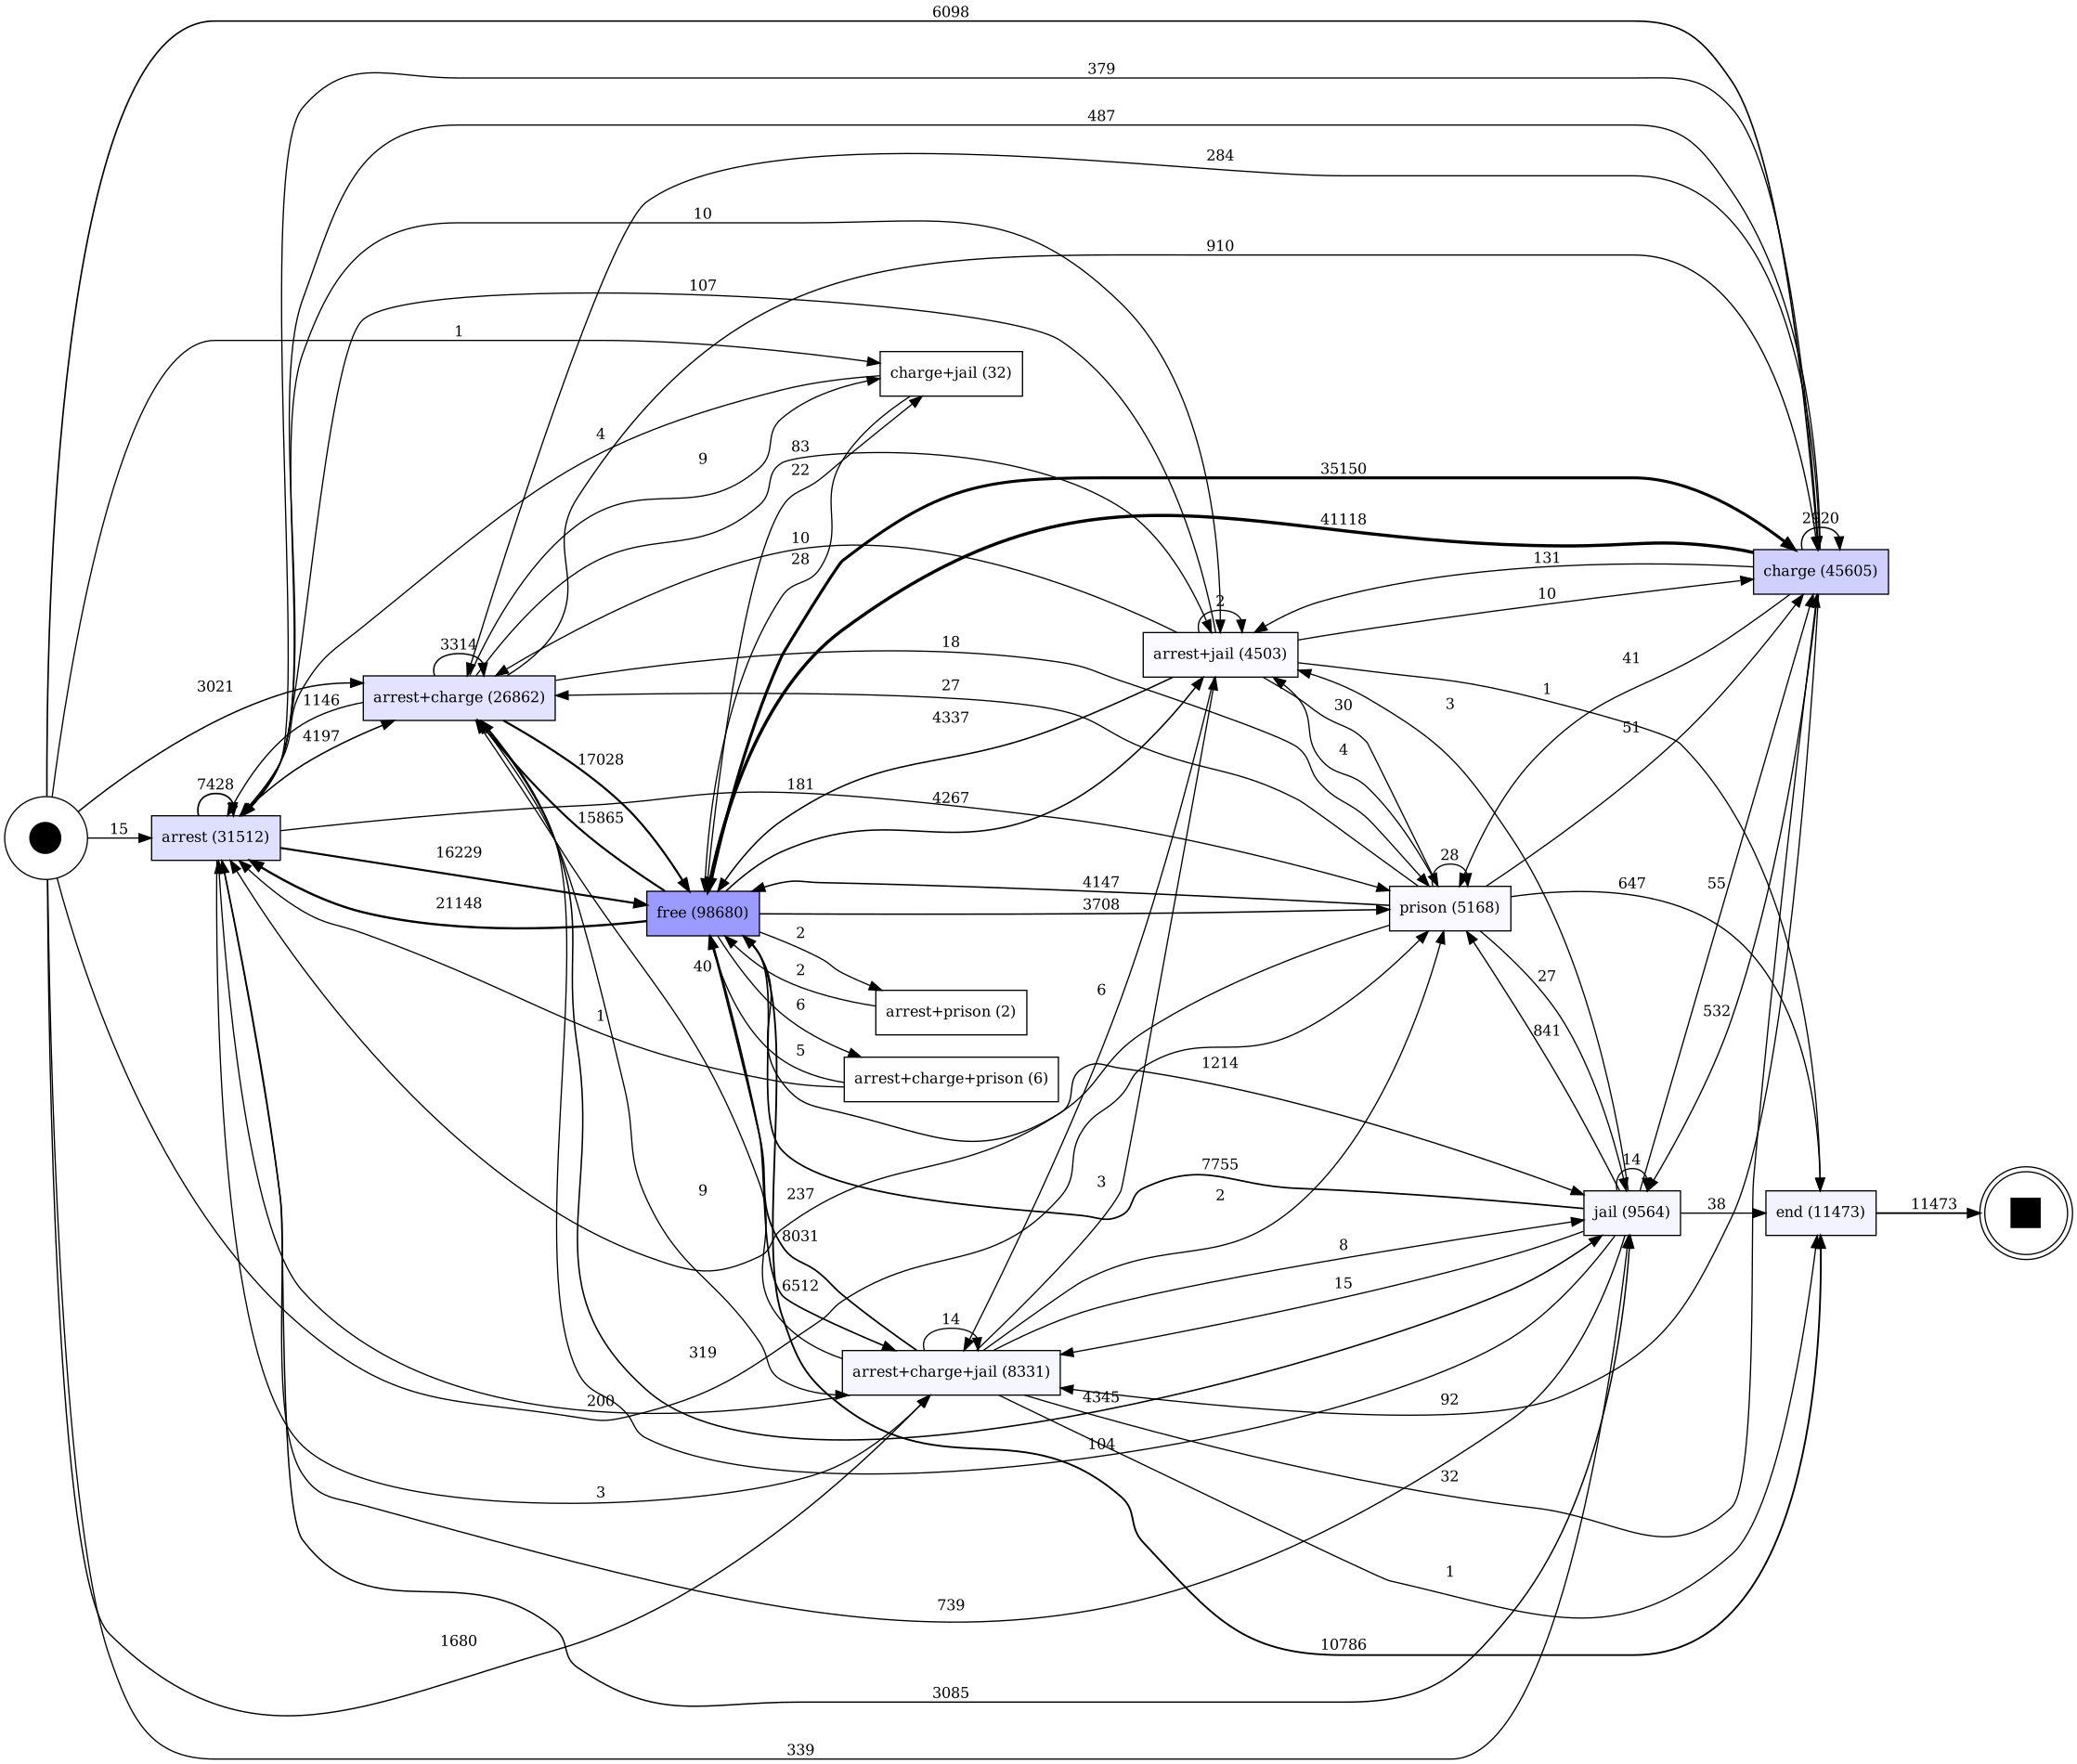

In [9]:
for m in BEST[1:]:
    p = V2 / f"net_{m}.png"
    if p.exists():
        print(m)
        display(Image(filename=str(p), width=1000))
p = V2 / "dfg_frequency.png"
if p.exists():
    print("DFG, частоты (весь журнал v2)")
    display(Image(filename=str(p), width=1000))

## 6. Выводы (вся история, версия 2)

**Здесь `LONG` = 180 заметно изменил Split Miner**, остальные модели — почти без изменений:

| Модель | fitness test v1 → v2 | precision test v1 → v2 | F1 TBR v1 → v2 |
|---|---|---|---|
| Split Miner | 0.720 → 0.761 | 0.884 → 0.811 | 0.793 → **0.785** |
| DFG p0.05 | 0.958 → 0.958 | 0.620 → 0.620 | 0.752 → 0.753 |
| IM 0.2 | 0.984 → 0.984 | 0.453 → 0.453 | 0.621 → 0.621 |
| HM 0.95 | 0.984 → 0.984 | 0.358 → 0.358 | 0.525 → 0.525 |

- **По F1 на token replay лучший — Split Miner (0.785)**, следом DFG p0.05 (0.753). Но у Split Miner
  без ошибок проходят только 7% трасс test (у DFG p0.05 — 50%), а alignments в версии 1 показали, что его сеть
  почти не воспроизводит трассы (alignment fitness 0.154). Без alignments для версии 2 выбор между ними открыт.
- **HM 0.9 / 0.95 / 0.99** — ни одна трасса не проходит без ошибок, precision 0.358.
- **Alpha+** — precision 0 (у Alpha+ на всей истории сеть вырожденная); IM 0, POWL, DFG без фильтра — почти цветочные.
- Переобучения нет: fitness на train и test совпадает до 0.003.

**Новое правило `end`:** как и в окне 2013, две трассы заканчиваются составным состоянием,
из ареста/обвинения напрямую в `end` — ни одной (последнее дело в базе — 30.03.2016).